# 05 · Fighter explorer & pound-for-pound rankings

A local prototype of the website's **fighter page**: search anyone who has fought in the UFC, then see their
profile, record, recent fights, and how their stats compare to their division.

Further down: **pound-for-pound rankings** at any date, and what the best fighters have in common.

All logic lives in `src/ufc/fighters.py` and `src/ufc/elo.py`, so the website can call the same functions later.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)

from ufc.fighters import FighterDB
from ufc import elo
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID
use_style()
db = FighterDB()
print(f"{len(db.directory):,} fighters · {len(db.fights):,} fights · data through {db.latest:%Y-%m-%d}")

2,777 fighters · 8,947 fights · data through 2026-10-17


In [2]:
GOOD, BAD = "#0ca30c", "#d03b3b"   # reserved status colors, always paired with the W/L text

def show_card(card):
    display(card.to_frame("").style.set_properties(**{"text-align": "left"})
            .set_table_styles([{"selector": "th", "props": "text-align:left; font-weight:600; padding-right:18px"}]))

def color_result(v):
    return {"W": f"color:{GOOD}; font-weight:700", "L": f"color:{BAD}; font-weight:700"}.get(v, "font-weight:700")

def show_fights(table):
    t = table.drop(columns="fight_id")
    display(t.style.map(color_result, subset=["Result"]).hide(axis="index"))

## 1 · Search
Search ignores accents and capitals, and also checks nicknames ("Borz", "Bones", "The Eagle").

In [3]:
display(db.search("adesanya"))
display(db.search("bones"))
display(db.search("the eagle"))

,nickname,division,ufc_fights,last_fight
Israel Adesanya,The Last Stylebender,Middleweight,19,2026-03-28


,nickname,division,ufc_fights,last_fight
Jon Jones,Bones,Heavyweight,24,2024-11-16


,nickname,division,ufc_fights,last_fight
Khabib Nurmagomedov,The Eagle,Lightweight,13,2020-10-24


Pick any name from a search result. **Change this one line to explore someone else.** Everything below follows it.

In [4]:
FIGHTER = "Israel Adesanya"
AS_OF = None   # e.g. "2022-07-03" to see the fighter as they were on that date

## 2 · Fighter card

In [5]:
show_card(db.card(FIGHTER, AS_OF))

,
Name,Israel Adesanya
Nickname,The Last Stylebender
Division,Middleweight
Age,37.2
Height,193 cm
Reach,203 cm
Stance,Switch
UFC record,13-6
Wins by,DEC 8 KO/TKO 5
Losses by,KO/TKO 3 DEC 2 SUB 1


## 3 · Last 5 fights
`Sig str` is significant strikes *landed/attempted*. `Opp Elo` is the opponent's rating going into the fight (how tough the opponent was), and `Elo ±` is how much the fight moved this fighter's rating.

In [6]:
last5 = db.last_fights(FIGHTER, n=5, as_of=AS_OF)
show_fights(last5)

Date,Event,Opponent,Result,Method,Rd,Time,Title,Sig str,Opp sig str,TD,Opp TD,KD,Ctrl,Opp ctrl,Opp Elo,Elo ±
2026-03-28,UFC Fight Night: Adesanya vs. Pyfer,Joe Pyfer,L,KO/TKO (Punches to Head From Mount),2,4:18,,42/75,36/70,0/2,2/8,0–0,0:00,2:44,1687,-43
2025-02-01,UFC Fight Night: Adesanya vs. Imavov,Nassourdine Imavov,L,KO/TKO (Punch to Head At Distance),2,0:30,,26/50,15/31,0/1,0/3,0–1,0:00,0:44,1729,-43
2024-08-17,UFC 305: Du Plessis vs. Adesanya,Dricus Du Plessis,L,Submission (Rear Naked Choke),4,3:38,🏆,97/203,90/197,0/1,4/9,0–0,0:09,3:39,1798,-40
2023-09-09,UFC 293: Adesanya vs. Strickland,Sean Strickland,L,Decision - Unanimous,5,5:00,🏆,94/271,137/259,0/0,0/0,0–1,0:00,0:14,1725,-42
2023-04-08,UFC 287: Pereira vs. Adesanya 2,Alex Pereira,W,KO/TKO (Punch to Head At Distance),2,4:21,🏆,41/96,49/85,0/0,0/0,1–0,0:03,0:00,1702,27


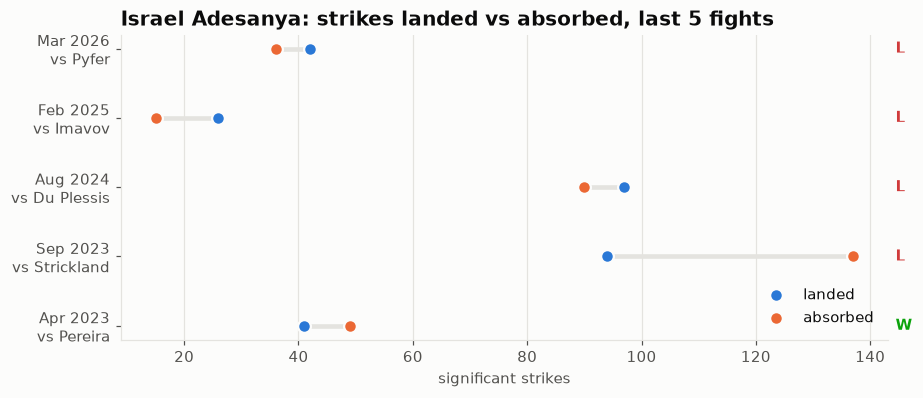

In [7]:
t = db.last_fights(FIGHTER, n=5, as_of=AS_OF, raw=True).iloc[::-1]
labels = [f"{d:%b %Y}\nvs {o.split(' ', 1)[-1]}" for d, o in zip(t.date, t.opponent)]
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hlines(y, t.opp_sig_str, t.sig_str, color=GRID, lw=3, zorder=1)
ax.scatter(t.sig_str, y, s=70, color=SERIES[0], label="landed", zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(t.opp_sig_str, y, s=70, color=SERIES[1], label="absorbed", zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for yi, res in zip(y, t.result):
    ax.text(1.01, yi, res, transform=ax.get_yaxis_transform(), va="center", fontweight="bold",
            color={"W": "#0ca30c", "L": "#d03b3b"}.get(res, INK_2))
ax.set_yticks(y, labels); ax.grid(axis="y", visible=False)
ax.set_xlabel("significant strikes"); ax.legend(loc="lower right")
ax.set_title(f"{FIGHTER}: strikes landed vs absorbed, last 5 fights")
plt.show()

### Round by round
Any fight from the table above, broken down by round (sig. strikes by target, takedowns, knockdowns, control seconds).

In [8]:
FIGHT = last5.fight_id.iloc[0]   # most recent; use .iloc[2] for the third row, etc.
db.fight_rounds(FIGHTER, FIGHT)

Israel Adesanya                                  Joe Pyfer                                 
              Sig str  Head Body Legs   TD   KD Ctrl s   Sig str  Head Body Legs   TD   KD Ctrl s
Round                                                                                            
1                24.0  13.0  2.0  9.0  0.0  0.0    0.0       9.0   7.0  1.0  1.0  1.0  0.0   61.0
2                18.0   9.0  6.0  3.0  0.0  0.0    0.0      27.0  26.0  1.0  0.0  1.0  0.0  103.0

## 4 · Stat profile vs the division
Raw stats aren't comparable across divisions (heavyweights land fewer strikes per minute than flyweights), so each stat is shown as a **percentile among active fighters in the same division**.
**100 = best in the division, 50 = typical.** Stats where lower is better (strikes absorbed, being knocked down) are flipped, so further right is always better.

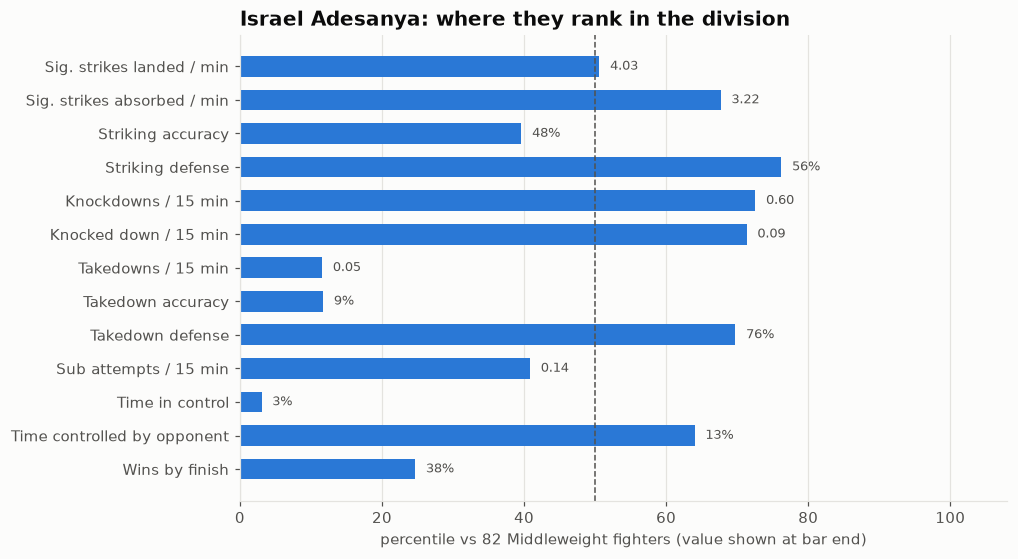

In [9]:
pct = db.percentiles(FIGHTER, AS_OF)
fmt = lambda s, v: f"{v:.0%}" if s in ("sig_acc","sig_def","td_acc","td_def","ctrl_share","ctrl_against","finish_rate") else f"{v:.2f}"
p = pct.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(p.label, p.percentile, color=SERIES[0], height=0.62)
ax.axvline(50, color=INK_2, lw=1, ls="--")
for i, (s, r) in enumerate(p.iterrows()):
    if pd.notna(r.percentile):
        ax.text(r.percentile + 1.5, i, fmt(s, r.value), va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 108); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"percentile vs {pct.attrs['peers']} {pct.attrs['division']} fighters (value shown at bar end)")
ax.set_title(f"{FIGHTER}: where they rank in the division")
plt.show()

### Fighting style: where the strikes land and from where

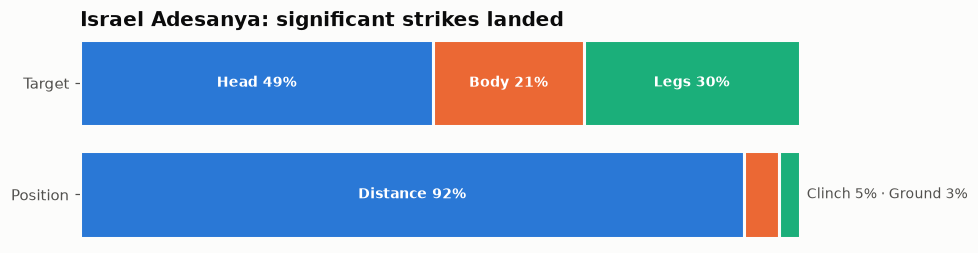

In [10]:
mix = db.style_mix(FIGHTER, AS_OF)
fig, axes = plt.subplots(2, 1, figsize=(9, 2.4))
for ax, part, title in [(axes[0], mix.iloc[:3], "Target"), (axes[1], mix.iloc[3:], "Position")]:
    left = 0
    for (label, v), c in zip(part.items(), SERIES[:3]):
        ax.barh(0, v, left=left, color=c, edgecolor="#fcfcfb", linewidth=2, height=0.6)
        if v >= 7:
            ax.text(left + v / 2, 0, f"{label} {v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += v
    small = [f"{label} {v:.0f}%" for label, v in part.items() if v < 7]
    if small:
        ax.text(101, 0, " · ".join(small), va="center", fontsize=9, color=INK_2, clip_on=False)
    ax.set_xlim(0, 100); ax.set_yticks([0], [title]); ax.grid(False); ax.set_xticks([])
    for s in ax.spines.values(): s.set_visible(False)
axes[0].set_title(f"{FIGHTER}: significant strikes landed")
plt.tight_layout(); plt.show()

## 5 · Rating history (Elo)
**Elo** is a chess-style rating. After every fight the winner takes points from the loser, and how many depends on how surprising the result was:
beating someone rated far above you is worth a lot, beating a newcomer very little. Everyone starts at 1500, finishes (KO/TKO, submission) move ratings 25% more than decisions, and weight class plays no part, so it works as a **pound-for-pound** measure.

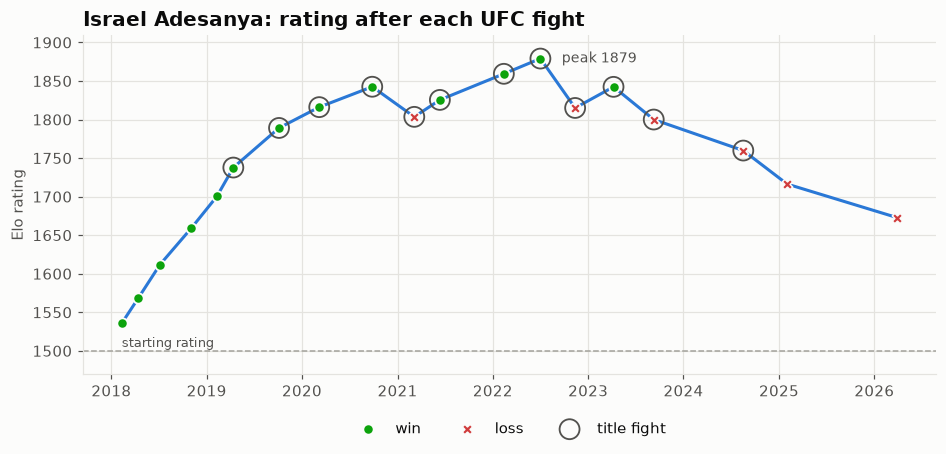

In [11]:
h = db.elo_history(FIGHTER)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(h.date, h.elo_post, color=SERIES[0], lw=2, zorder=2)
w, l = h[h.result == "W"], h[h.result == "L"]
ax.scatter(w.date, w.elo_post, s=46, color="#0ca30c", label="win", zorder=3, edgecolor="#fcfcfb", linewidth=1.2)
ax.scatter(l.date, l.elo_post, s=46, color="#d03b3b", marker="X", label="loss", zorder=3, edgecolor="#fcfcfb", linewidth=1)
t = h[h.is_title_bout == 1]
ax.scatter(t.date, t.elo_post, s=170, facecolors="none", edgecolors=INK_2, linewidth=1.2, label="title fight", zorder=4)
ax.axhline(1500, color=NEUTRAL, lw=1, ls="--"); ax.text(h.date.min(), 1505, "starting rating", color=INK_2, fontsize=8.5)
pk = h.loc[h.elo_post.idxmax()]
ax.annotate(f"peak {pk.elo_post:.0f}", (pk.date, pk.elo_post), xytext=(14, 0), textcoords="offset points",
            ha="left", va="center", fontsize=9, color=INK_2)
lo, hi = min(1500, h.elo_post.min()), h.elo_post.max()
ax.set_ylim(lo - 30, hi + 0.08 * (hi - lo))
ax.set_ylabel("Elo rating"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title(f"{FIGHTER}: rating after each UFC fight")
plt.show()

## 6 · Search box (website preview)
Type a name and press Enter to see their card and last 5 fights. This needs a live Jupyter session (it won't render on a static page).

In [12]:
import ipywidgets as w
box = w.Combobox(placeholder="Type a fighter's name…", options=sorted(db.directory.index), ensure_option=True,
                 layout=w.Layout(width="360px"))
out = w.Output()
def on_pick(change):
    with out:
        out.clear_output()
        if change["new"] in db.directory.index:
            show_card(db.card(change["new"])); show_fights(db.last_fights(change["new"]))
box.observe(on_pick, names="value")
display(w.VBox([box, out]))

## 7 · Pound-for-pound rankings
Highest Elo among **active** fighters (fought in the last 18 months, at least 5 UFC fights). Men's and women's lists are separate.

**Limitations:**
- Retirements aren't in the data, so a retired champion stays listed until the 18-month window passes.
- Only UFC fights count. A star signed from another promotion starts at 1500.
- A fighter who keeps beating low-rated opponents climbs slowly, which is a feature, not a bug.

In [13]:
print(f"Men's P4P, as of {db.latest:%Y-%m-%d}")
display(elo.p4p(db.hist, n=15))
print("Women's P4P")
display(elo.p4p(db.hist, n=10, gender="Women"))

Men's P4P, as of 2026-10-17


,fighter,elo,ufc_record,division,last_fight,last_result
rank,,,,,,
1,Islam Makhachev,2022,18-1,Welterweight,2026-08-15,W vs Ian Machado Garry
2,Charles Oliveira,1890,25-11 (1 NC),Lightweight,2026-03-07,W vs Max Holloway
3,Max Holloway,1870,24-9,Welterweight,2026-07-11,W vs Conor McGregor
4,Ciryl Gane,1867,11-2 (1 NC),Heavyweight,2026-06-14,W vs Alex Pereira
5,Dricus Du Plessis,1862,10-1,Middleweight,2026-07-18,W vs Kamaru Usman
6,Justin Gaethje,1861,11-5,Lightweight,2026-06-14,W vs Ilia Topuria
7,Alexander Volkanovski,1854,15-3,Featherweight,2026-01-31,W vs Diego Lopes
8,Merab Dvalishvili,1851,14-3,Bantamweight,2025-12-06,L vs Petr Yan
9,Aljamain Sterling,1847,18-5,Featherweight,2026-04-25,W vs Youssef Zalal


Women's P4P


,fighter,elo,ufc_record,division,last_fight,last_result
rank,,,,,,
1,Valentina Shevchenko,1835,15-3-1,Women's Flyweight,2025-11-15,W vs Zhang Weili
2,Natalia Silva,1769,9-0,Women's Flyweight,2026-10-03,W vs Wang Cong
3,Zhang Weili,1761,10-3,Women's Flyweight,2025-11-15,L vs Valentina Shevchenko
4,Tatiana Suarez,1757,9-1,Women's Strawweight,2026-04-11,W vs Loopy Godinez
5,Alexa Grasso,1729,10-5-1,Women's Flyweight,2026-09-12,W vs Manon Fiorot
6,Jasmine Jasudavicius,1722,10-3,Women's Flyweight,2026-10-17,W vs Erin Blanchfield
7,Erin Blanchfield,1713,8-2,Women's Flyweight,2026-10-17,L vs Jasmine Jasudavicius
8,Mackenzie Dern,1713,12-5,Women's Strawweight,2026-08-15,W vs Gillian Robertson
9,Manon Fiorot,1710,8-2,Women's Flyweight,2026-09-12,L vs Alexa Grasso


### Time machine
P4P as it stood on any date, using only fights up to that day.

In [14]:
for date in ["2010-01-01", "2015-01-01", "2020-01-01"]:
    print(f"Men's P4P top 5 as of {date}")
    display(elo.p4p(db.hist, date, n=5))

Men's P4P top 5 as of 2010-01-01


,fighter,elo,ufc_record,division,last_fight,last_result
rank,,,,,,
1,Georges St-Pierre,1861,13-2,Welterweight,2009-07-11,W vs Thiago Alves
2,Anderson Silva,1827,10-0,Light Heavyweight,2009-08-08,W vs Forrest Griffin
3,BJ Penn,1783,11-4-1,Lightweight,2009-12-12,W vs Diego Sanchez
4,Lyoto Machida,1768,8-0,Light Heavyweight,2009-10-24,W vs Mauricio Rua
5,Jon Fitch,1755,11-1,Welterweight,2009-12-12,W vs Mike Pierce


Men's P4P top 5 as of 2015-01-01


,fighter,elo,ufc_record,division,last_fight,last_result
rank,,,,,,
1,Georges St-Pierre,1947,19-2,Welterweight,2013-11-16,W vs Johny Hendricks
2,Jon Jones,1913,14-1,Light Heavyweight,2014-04-26,W vs Glover Teixeira
3,Chris Weidman,1836,8-0,Middleweight,2014-07-05,W vs Lyoto Machida
4,Cain Velasquez,1820,11-1,Heavyweight,2013-10-19,W vs Junior Dos Santos
5,Anderson Silva,1815,16-2,Middleweight,2013-12-28,L vs Chris Weidman


Men's P4P top 5 as of 2020-01-01


,fighter,elo,ufc_record,division,last_fight,last_result
rank,,,,,,
1,Jon Jones,1979,19-1 (1 NC),Light Heavyweight,2019-07-06,W vs Thiago Santos
2,Tony Ferguson,1906,15-1,Lightweight,2019-06-08,W vs Donald Cerrone
3,Khabib Nurmagomedov,1885,12-0,Lightweight,2019-09-07,W vs Dustin Poirier
4,Stipe Miocic,1871,13-3,Heavyweight,2019-08-17,W vs Daniel Cormier
5,Kamaru Usman,1866,11-0,Welterweight,2019-12-14,W vs Colby Covington


### All-time peak ratings
Each fighter's highest rating ever. A rough "greatest of all time" list, with the caveat that it rewards long win streaks against strong opposition.

In [15]:
display(elo.peak_elo(db.hist, n=15))
display(elo.peak_elo(db.hist, n=5, gender="Women"))

,fighter,peak_elo,peak_date,record_at_peak,division
rank,,,,,
1,Jon Jones,2032,2024-11-16,22-1 (1 NC),Heavyweight
2,Islam Makhachev,2022,2026-08-15,18-1,Welterweight
3,Georges St-Pierre,1970,2017-11-04,20-2,Middleweight
4,Kamaru Usman,1960,2021-11-06,15-0,Welterweight
5,Anderson Silva,1931,2012-10-13,16-0,Light Heavyweight
6,Leon Edwards,1923,2023-12-16,14-2 (1 NC),Welterweight
7,Charles Oliveira,1921,2022-05-07,21-8 (1 NC),Lightweight
8,Alexander Volkanovski,1910,2022-07-02,12-0,Featherweight
9,Khabib Nurmagomedov,1909,2020-10-24,13-0,Lightweight


,fighter,peak_elo,peak_date,record_at_peak,division
rank,,,,,
1,Amanda Nunes,1845,2021-03-06,14-1,Women's Featherweight
2,Valentina Shevchenko,1835,2025-11-15,15-3-1,Women's Flyweight
3,Zhang Weili,1791,2025-02-08,10-2,Women's Strawweight
4,Natalia Silva,1769,2026-10-03,9-0,Women's Flyweight
5,Tatiana Suarez,1757,2026-04-11,9-1,Women's Strawweight


## 8 · What do the best fighters have in common?
For each P4P top-15 list, take every fighter's **division percentile** on each stat and average them.
A stat where the elite average sits far above 50 is something the best fighters reliably do better than their peers.
Repeating this at several dates checks the pattern isn't a one-off.

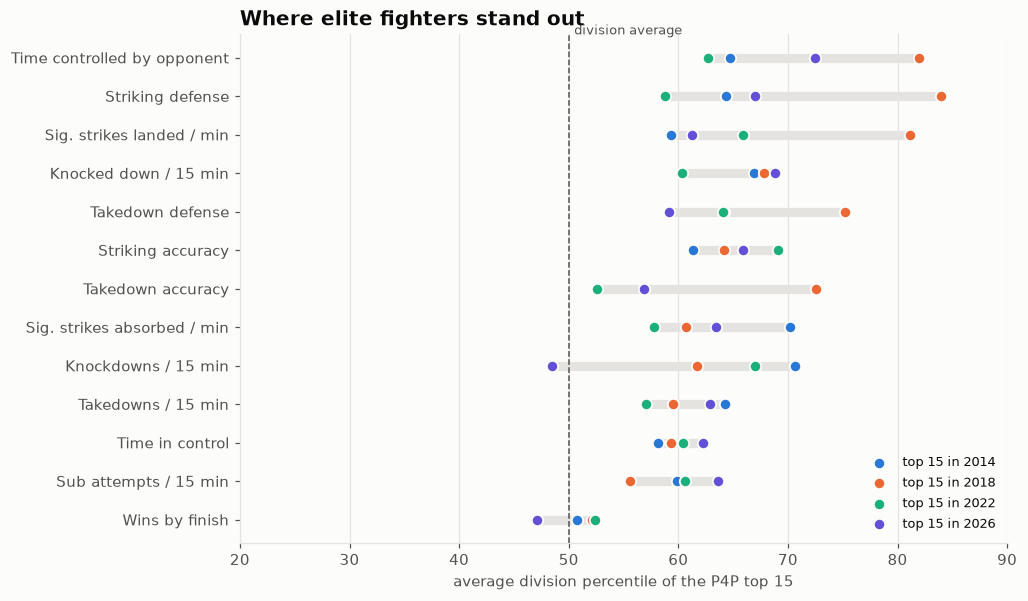

,2014,2018,2022,2026
Wins by finish,51.0,52.0,52.0,47.0
Sub attempts / 15 min,60.0,56.0,61.0,64.0
Time in control,58.0,59.0,60.0,62.0
Takedowns / 15 min,64.0,59.0,57.0,63.0
Knockdowns / 15 min,71.0,62.0,67.0,48.0
Sig. strikes absorbed / min,70.0,61.0,58.0,63.0
Takedown accuracy,73.0,73.0,53.0,57.0
Striking accuracy,61.0,64.0,69.0,66.0
Takedown defense,64.0,75.0,64.0,59.0
Knocked down / 15 min,67.0,68.0,60.0,69.0


In [16]:
def elite_profile(as_of, n=15):
    top = elo.p4p(db.hist, as_of, n=n).fighter
    return pd.concat([db.percentiles(f, as_of).percentile for f in top], axis=1).mean(axis=1)

dates = ["2014-01-01", "2018-01-01", "2022-01-01", f"{db.latest:%Y-%m-%d}"]
prof = pd.DataFrame({d[:4]: elite_profile(d) for d in dates})
prof.index = [lbl for col, lbl, _ in __import__("ufc.fighters", fromlist=["STATS"]).STATS]
prof = prof.loc[prof.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(prof))
ax.hlines(y, prof.min(axis=1), prof.max(axis=1), color=GRID, lw=6, zorder=1)
for (col, vals), c in zip(prof.items(), [SERIES[0], SERIES[1], SERIES[2], SERIES[6]]):
    ax.scatter(vals, y, s=55, color=c, label=f"top 15 in {col}", zorder=3, edgecolor="#fcfcfb", linewidth=1.2)
ax.axvline(50, color=INK_2, lw=1, ls="--"); ax.text(50.5, len(prof) - 0.4, "division average", color=INK_2, fontsize=8.5)
ax.set_yticks(y, prof.index); ax.grid(axis="y", visible=False); ax.set_xlim(20, 90)
ax.set_xlabel("average division percentile of the P4P top 15")
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("Where elite fighters stand out")
plt.show()
prof.round(0)

### Do raw numbers tell the same story?
Elite medians vs all active fighters, for the latest date.

In [17]:
cs = db.career_stats()
active = cs[(cs.ufc_fights >= 5) & (cs.last_fight >= db.latest - pd.DateOffset(months=18))]
top = active.loc[elo.p4p(db.hist, n=15).fighter]
cols = ["slpm", "sapm", "sig_acc", "sig_def", "td_per15", "td_def", "ctrl_share", "ctrl_against", "finish_rate"]
pd.DataFrame({"P4P top 15 (median)": top[cols].median(), "all active (median)": active[cols].median()}).round(2)

,P4P top 15 (median),all active (median)
slpm,4.42,4.04
sapm,3.05,3.69
sig_acc,0.52,0.48
sig_def,0.55,0.54
td_per15,1.73,1.11
td_def,0.73,0.67
ctrl_share,0.28,0.17
ctrl_against,0.07,0.17
finish_rate,0.60,0.50


## 9 · Is Elo a good *predictor*?
A good ranking tool isn't automatically a good predictor. Here we test "the higher-rated fighter wins" on the same 2024–2026 fights used in notebook 04,
then add the Elo difference as a feature to the notebook-04 logistic model.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from ufc.features import MIN_FEATURES, HIST_FEATURES, Clipper, swap_corners

print("Elo K-factor tuning on 2010-03 → 2023 (best 5 by log loss):")
display(elo.tune(db.fights, ks=(32, 48, 64, 80), mults=(1.0, 1.25, 1.5)).head(5).round(4))

SPLIT = pd.Timestamp("2024-01-01")
t = pd.read_parquet("data/processed/model_table.parquet")
pre = db.hist.pivot_table(index="fight_id", columns="corner", values="elo_pre")
t["elo_diff"] = t.fight_id.map(pre.Red - pre.Blue)
train, test = t[t.date < SPLIT], t[t.date >= SPLIT]

def fit_eval(cols):
    aug = pd.concat([train.assign(red_corner=1), swap_corners(train).assign(red_corner=-1)])
    m = make_pipeline(Clipper(0.01, 0.99), SimpleImputer(strategy="median", add_indicator=True),
                      StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))
    m.fit(aug[cols + ["red_corner"]], aug.red_win)
    p = m.predict_proba(test.assign(red_corner=1)[cols + ["red_corner"]])[:, 1]
    return p

base = [f + "_diff" for f in MIN_FEATURES + HIST_FEATURES] + ["r_debut", "b_debut", "reach_missing"]
p_elo = elo.expected(test.fight_id.map(pre.Red), test.fight_id.map(pre.Blue))
rows = {
    "always pick Red": np.full(len(test), train.red_win.mean()),
    "Elo only": p_elo.values,
    "notebook-04 model": fit_eval(base),
    "notebook-04 model + Elo": fit_eval(base + ["elo_diff"]),
}
pd.DataFrame({k: {"accuracy": accuracy_score(test.red_win, p > 0.5), "log_loss": log_loss(test.red_win, p),
                  "roc_auc": roc_auc_score(test.red_win, p) if np.std(p) > 0 else 0.5}
              for k, p in rows.items()}).T.round(3)

Elo K-factor tuning on 2010-03 → 2023 (best 5 by log loss):


,k,finish_mult,fights,accuracy,log_loss
0,64,1.25,6027,0.5621,0.6814
1,64,1.50,6027,0.5635,0.6817
2,48,1.50,6027,0.5595,0.6818
3,80,1.25,6027,0.5626,0.6818
4,64,1.00,6027,0.5582,0.6820


,accuracy,log_loss,roc_auc
always pick Red,0.551,0.690,0.500
Elo only,0.560,0.680,0.578
notebook-04 model,0.642,0.640,0.684
notebook-04 model + Elo,0.637,0.637,0.691


**Reading this:** Elo alone is a modest predictor in MMA, because it knows nothing about age, size, or matchups. That's why it ranks well but predicts only so-so.
What matters is whether it adds *new* information on top of the other features. Compare the last two rows: that's the honest test of a new feature.
In the simulator, Elo will be one input among several, not the whole story.